In [3]:
df = pd.read_csv("../dataset/raw_sales.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [4]:
print("Rows and columns:", df.shape)


Rows and columns: (10800, 21)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
print(df.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quanti

In [7]:
print(df.isnull().sum())

Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64


In [8]:
print(df.isnull().sum())

Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64


In [9]:
df.describe()

,Postal Code,Sales,Quantity,Discount,Profit
count,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55245.233297,229.858001,3.789574,0.156203,28.656896
std,32038.715955,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,57103.000000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [10]:
# Separate actual sales transactions
sales_df = df[df["Order Date"].notna()].copy()

# Keep supplementary records separately
other_df = df[df["Order Date"].isna()].copy()

print("Original dataset:", df.shape)
print("Sales transactions:", sales_df.shape)
print("Supplementary records:", other_df.shape)

Original dataset: (10800, 21)
Sales transactions: (9994, 21)
Supplementary records: (806, 21)


In [11]:
print("Missing values in sales data:")
print(sales_df.isnull().sum())

print("\nDuplicate records:", sales_df.duplicated().sum())

sales_df.head()

Missing values in sales data:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

Duplicate records: 0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [12]:
# Display rows with missing Postal Code
missing_postal = sales_df[sales_df["Postal Code"].isna()]

print("Rows with missing Postal Code:", len(missing_postal))
missing_postal[["Row ID", "Order ID", "Customer Name", "City", "State", "Region", "Postal Code"]]

Rows with missing Postal Code: 11


,Row ID,Order ID,Customer Name,City,State,Region,Postal Code
2234,2235,CA-2018-104066,Quincy Jones,Burlington,Vermont,East,NaN
5274,5275,CA-2016-162887,Stewart Visinsky,Burlington,Vermont,East,NaN
8798,8799,US-2017-150140,Valerie Mitchum,Burlington,Vermont,East,NaN
9146,9147,US-2017-165505,Claudia Bergmann,Burlington,Vermont,East,NaN
9147,9148,US-2017-165505,Claudia Bergmann,Burlington,Vermont,East,NaN
9148,9149,US-2017-165505,Claudia Bergmann,Burlington,Vermont,East,NaN
9386,9387,US-2018-127292,Raymond Messe,Burlington,Vermont,East,NaN
9387,9388,US-2018-127292,Raymond Messe,Burlington,Vermont,East,NaN
9388,9389,US-2018-127292,Raymond Messe,Burlington,Vermont,East,NaN
9389,9390,US-2018-127292,Raymond Messe,Burlington,Vermont,East,NaN


In [13]:
# Convert date columns into datetime format
sales_df["Order Date"] = pd.to_datetime(sales_df["Order Date"])
sales_df["Ship Date"] = pd.to_datetime(sales_df["Ship Date"])

print(sales_df[["Order Date", "Ship Date"]].dtypes)

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [14]:
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   object        
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9983 non-null   float64       
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 non-nu

In [15]:
# Convert columns into appropriate data types
sales_df["Row ID"] = sales_df["Row ID"].astype("int64")
sales_df["Quantity"] = sales_df["Quantity"].astype("int64")

# Keep Postal Code as nullable integer
sales_df["Postal Code"] = sales_df["Postal Code"].astype("Int64")

print(sales_df.dtypes)

Row ID                    int64
Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code               Int64
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object


In [16]:
sales_df[["Sales", "Quantity", "Discount", "Profit"]].describe()


,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [17]:
# Save cleaned dataset
sales_df.to_csv("../dataset/cleaned_sales.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final dataset shape:", sales_df.shape)

Cleaned dataset saved successfully!
Final dataset shape: (9994, 21)


In [19]:
# Statistical summary of numerical columns
sales_df[["Sales", "Quantity", "Discount", "Profit"]].describe()

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [20]:
# Overall business performance

total_sales = sales_df["Sales"].sum()
total_profit = sales_df["Profit"].sum()
total_orders = sales_df["Order ID"].nunique()
total_customers = sales_df["Customer ID"].nunique()
total_quantity = sales_df["Quantity"].sum()

print("TOTAL SALES:", round(total_sales, 2))
print("TOTAL PROFIT:", round(total_profit, 2))
print("TOTAL ORDERS:", total_orders)
print("TOTAL CUSTOMERS:", total_customers)
print("TOTAL QUANTITY SOLD:", total_quantity)

profit_margin = (total_profit / total_sales) * 100
print("PROFIT MARGIN:", round(profit_margin, 2), "%")

TOTAL SALES: 2297200.86
TOTAL PROFIT: 286397.02
TOTAL ORDERS: 5009
TOTAL CUSTOMERS: 793
TOTAL QUANTITY SOLD: 37873
PROFIT MARGIN: 12.47 %


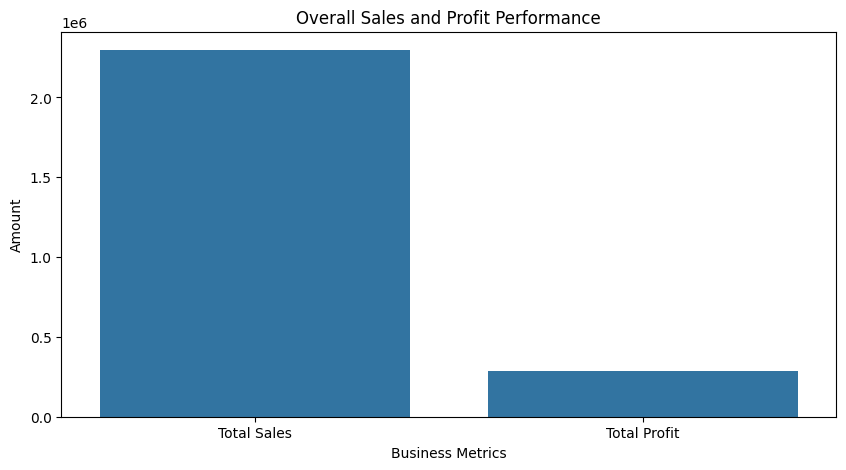

In [21]:
# Sales and Profit Overview

plt.figure(figsize=(10, 5))

sns.barplot(
    x=["Total Sales", "Total Profit"],
    y=[total_sales, total_profit]
)

plt.title("Overall Sales and Profit Performance")
plt.ylabel("Amount")
plt.xlabel("Business Metrics")
plt.show()

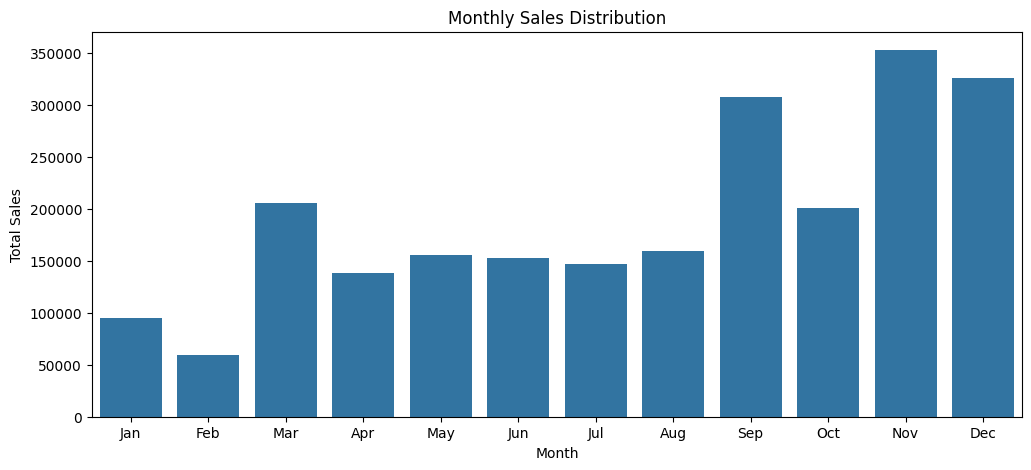

In [22]:
# Extract month and year
sales_df["Year"] = sales_df["Order Date"].dt.year
sales_df["Month"] = sales_df["Order Date"].dt.month

# Calculate monthly sales
monthly_sales = (
    sales_df.groupby("Month")["Sales"]
    .sum()
    .reset_index()
)

# Plot monthly sales
plt.figure(figsize=(12, 5))

sns.barplot(
    data=monthly_sales,
    x="Month",
    y="Sales"
)

plt.title("Monthly Sales Distribution")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(range(12), [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])

plt.show()

In [23]:
# Display monthly sales values
monthly_sales.sort_values(
    by="Sales",
    ascending=False
)

,Month,Sales
10,11,352461.0710
11,12,325293.5035
8,9,307649.9457
2,3,205005.4888
9,10,200322.9847
7,8,159044.0630
4,5,155028.8117
5,6,152718.6793
6,7,147238.0970
3,4,137762.1286


In [24]:
# Category-wise sales and profit
category_sales = (
    sales_df.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
    .sort_values(by="Total_Sales", ascending=False)
)

category_sales

,Category,Total_Sales,Total_Profit,Total_Quantity
2,Technology,836154.0330,145454.9481,6939
0,Furniture,741999.7953,18451.2728,8028
1,Office Supplies,719047.0320,122490.8008,22906


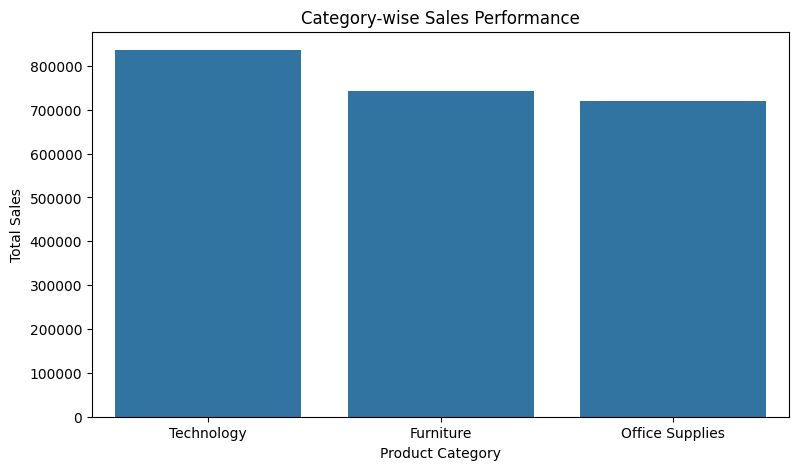

In [25]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_sales,
    x="Category",
    y="Total_Sales"
)

plt.title("Category-wise Sales Performance")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")

plt.show()

In [26]:
# Sub-category performance analysis

subcategory_sales = (
    sales_df.groupby("Sub-Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
    .sort_values(by="Total_Sales", ascending=False)
)

subcategory_sales

,Sub-Category,Total_Sales,Total_Profit,Total_Quantity
13,Phones,330007.0540,44515.7306,3289
5,Chairs,328449.1030,26590.1663,2356
14,Storage,223843.6080,21278.8264,3158
16,Tables,206965.5320,-17725.4811,1241
3,Binders,203412.7330,30221.7633,5974
11,Machines,189238.6310,3384.7569,440
0,Accessories,167380.3180,41936.6357,2976
6,Copiers,149528.0300,55617.8249,234
4,Bookcases,114879.9963,-3472.5560,868
1,Appliances,107532.1610,18138.0054,1729


In [27]:
# Find the most profitable sub-categories

subcategory_sales.sort_values(
    by="Total_Profit",
    ascending=False
)

,Sub-Category,Total_Sales,Total_Profit,Total_Quantity
6,Copiers,149528.0300,55617.8249,234
13,Phones,330007.0540,44515.7306,3289
0,Accessories,167380.3180,41936.6357,2976
12,Paper,78479.2060,34053.5693,5178
3,Binders,203412.7330,30221.7633,5974
5,Chairs,328449.1030,26590.1663,2356
14,Storage,223843.6080,21278.8264,3158
1,Appliances,107532.1610,18138.0054,1729
9,Furnishings,91705.1640,13059.1436,3563
7,Envelopes,16476.4020,6964.1767,906


In [28]:
# Find sub-categories generating losses

subcategory_sales[subcategory_sales["Total_Profit"] < 0]

,Sub-Category,Total_Sales,Total_Profit,Total_Quantity
16,Tables,206965.5320,-17725.4811,1241
4,Bookcases,114879.9963,-3472.5560,868
15,Supplies,46673.5380,-1189.0995,647


In [29]:
# Regional sales and profit analysis

region_sales = (
    sales_df.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .reset_index()
    .sort_values(by="Total_Sales", ascending=False)
)

region_sales

,Region,Total_Sales,Total_Profit,Total_Orders
3,West,725457.8245,108418.4489,1611
1,East,678781.2400,91522.7800,1401
0,Central,501239.8908,39706.3625,1175
2,South,391721.9050,46749.4303,822


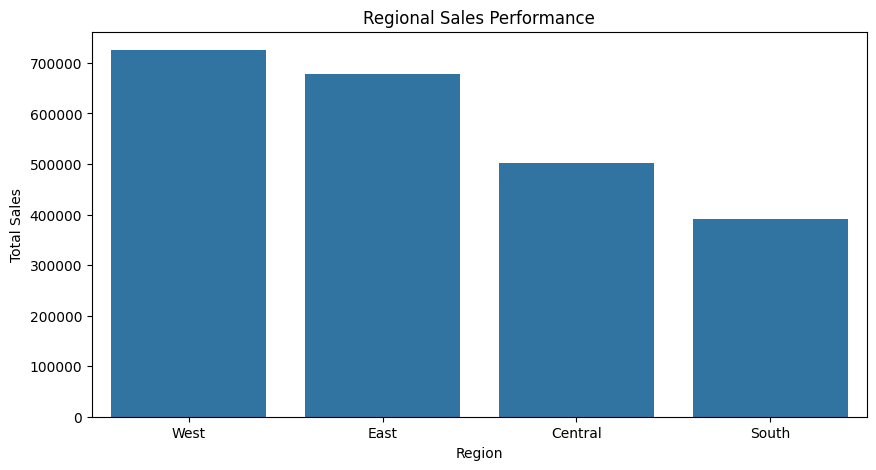

In [30]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=region_sales,
    x="Region",
    y="Total_Sales"
)

plt.title("Regional Sales Performance")
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.show()

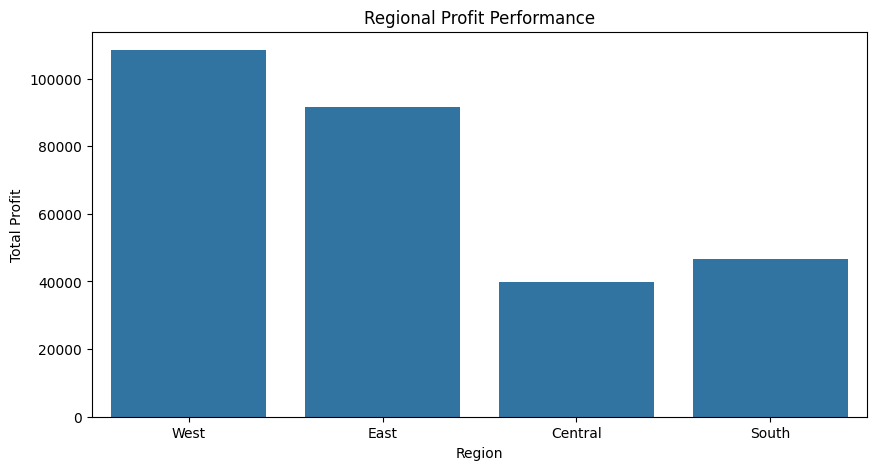

In [31]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=region_sales,
    x="Region",
    y="Total_Profit"
)

plt.title("Regional Profit Performance")
plt.xlabel("Region")
plt.ylabel("Total Profit")

plt.show()

In [32]:
# Customer purchase analysis

customer_analysis = (
    sales_df.groupby("Customer Name")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .reset_index()
    .sort_values(by="Total_Sales", ascending=False)
)

# Top 10 customers by sales
customer_analysis.head(10)

,Customer Name,Total_Sales,Total_Profit,Total_Orders
686,Sean Miller,25043.050,-1980.7393,5
730,Tamara Chand,19052.218,8981.3239,5
622,Raymond Buch,15117.339,6976.0959,6
757,Tom Ashbrook,14595.620,4703.7883,4
6,Adrian Barton,14473.571,5444.8055,10
441,Ken Lonsdale,14175.229,806.8550,12
671,Sanjit Chand,14142.334,5757.4119,9
334,Hunter Lopez,12873.298,5622.4292,6
672,Sanjit Engle,12209.438,2650.6769,11
156,Christopher Conant,12129.072,2177.0493,5


In [33]:
customer_analysis.sort_values(
    by="Total_Profit",
    ascending=False
).head(10)

,Customer Name,Total_Sales,Total_Profit,Total_Orders
730,Tamara Chand,19052.218,8981.3239,5
622,Raymond Buch,15117.339,6976.0959,6
671,Sanjit Chand,14142.334,5757.4119,9
334,Hunter Lopez,12873.298,5622.4292,6
6,Adrian Barton,14473.571,5444.8055,10
757,Tom Ashbrook,14595.620,4703.7883,4
157,Christopher Martinez,8954.020,3899.8904,4
431,Keith Dawkins,8181.256,3038.6254,12
35,Andy Reiter,6608.448,2884.6208,6
194,Daniel Raglin,8350.868,2869.0760,8


In [34]:
print("Total unique customers:", sales_df["Customer ID"].nunique())

print(
    "Average sales per customer:",
    round(sales_df.groupby("Customer ID")["Sales"].sum().mean(), 2)
)

Total unique customers: 793
Average sales per customer: 2896.85


In [35]:
# Group discounts into ranges

sales_df["Discount_Range"] = pd.cut(
    sales_df["Discount"],
    bins=[-0.01, 0, 0.1, 0.2, 0.3, 0.5, 1],
    labels=[
        "0%",
        "1-10%",
        "11-20%",
        "21-30%",
        "31-50%",
        "Above 50%"
    ]
)

# Analyze discount impact

discount_analysis = (
    sales_df.groupby("Discount_Range", observed=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Profit=("Profit", "mean"),
        Transaction_Count=("Order ID", "count")
    )
    .reset_index()
)

discount_analysis

,Discount_Range,Total_Sales,Total_Profit,Average_Profit,Transaction_Count
0,0%,1.087908e+06,320987.6032,66.900292,4798
1,1-10%,5.436935e+04,9029.1770,96.055074,94
2,11-20%,7.921529e+05,91756.2975,24.738824,3709
3,21-30%,1.032267e+05,-10369.2774,-45.679636,227
4,31-50%,1.953148e+05,-48447.7273,-156.282991,310
5,Above 50%,6.422874e+04,-76559.0513,-89.438144,856


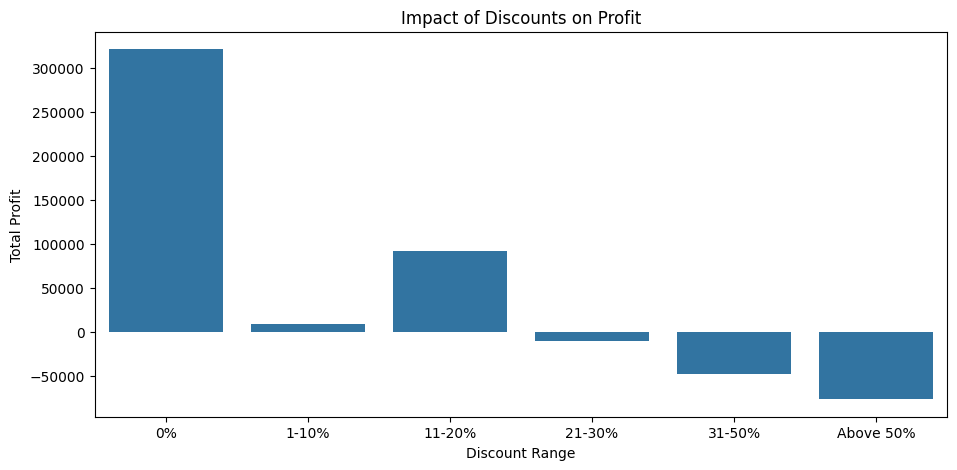

In [36]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=discount_analysis,
    x="Discount_Range",
    y="Total_Profit"
)

plt.title("Impact of Discounts on Profit")
plt.xlabel("Discount Range")
plt.ylabel("Total Profit")

plt.show()

In [37]:
# Discount impact across product categories

category_discount = (
    sales_df.groupby(["Category", "Discount"], as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Transaction_Count=("Order ID", "count")
    )
)

category_discount.sort_values(
    by="Total_Profit",
    ascending=True
)

,Category,Discount,Total_Sales,Total_Profit,Transaction_Count
15,Office Supplies,0.80,16963.7560,-30539.0392,300
22,Technology,0.70,15601.5090,-19579.3191,23
14,Office Supplies,0.70,22559.3910,-16601.0984,380
6,Furniture,0.40,45614.4060,-16187.3968,75
8,Furniture,0.50,20983.4700,-12871.1990,54
4,Furniture,0.30,99470.3500,-10695.3169,222
21,Technology,0.50,37935.0700,-7635.2291,12
20,Technology,0.40,70803.3780,-6869.6536,131
9,Furniture,0.60,6644.7000,-5944.6552,138
10,Furniture,0.70,2459.3820,-3894.9394,15


In [38]:
# Executive business summary

print("========== RETAIL SALES ANALYSIS ==========")

print("Total Sales:", round(sales_df["Sales"].sum(), 2))
print("Total Profit:", round(sales_df["Profit"].sum(), 2))

print("\nBEST PERFORMING CATEGORY:")
print(category_sales.loc[category_sales["Total_Sales"].idxmax()])

print("\nMOST PROFITABLE SUB-CATEGORY:")
print(subcategory_sales.loc[subcategory_sales["Total_Profit"].idxmax()])

print("\nHIGHEST SALES REGION:")
print(region_sales.loc[region_sales["Total_Sales"].idxmax()])

print("\nLOWEST PROFIT SUB-CATEGORY:")
print(subcategory_sales.loc[subcategory_sales["Total_Profit"].idxmin()])

print("\nHIGHEST SALES MONTH:")
print(monthly_sales.loc[monthly_sales["Sales"].idxmax()])

========== RETAIL SALES ANALYSIS ==========
Total Sales: 2297200.86
Total Profit: 286397.02

BEST PERFORMING CATEGORY:
Category           Technology
Total_Sales        836154.033
Total_Profit      145454.9481
Total_Quantity           6939
Name: 2, dtype: object

MOST PROFITABLE SUB-CATEGORY:
Sub-Category         Copiers
Total_Sales        149528.03
Total_Profit      55617.8249
Total_Quantity           234
Name: 6, dtype: object

HIGHEST SALES REGION:
Region                 West
Total_Sales     725457.8245
Total_Profit    108418.4489
Total_Orders           1611
Name: 3, dtype: object

LOWEST PROFIT SUB-CATEGORY:
Sub-Category          Tables
Total_Sales       206965.532
Total_Profit     -17725.4811
Total_Quantity          1241
Name: 16, dtype: object

HIGHEST SALES MONTH:
Month        11.000
Sales    352461.071
Name: 10, dtype: float64


In [39]:
# Export analysis results

category_sales.to_csv("../dataset/category_analysis.csv", index=False)

subcategory_sales.to_csv("../dataset/subcategory_analysis.csv", index=False)

region_sales.to_csv("../dataset/region_analysis.csv", index=False)

customer_analysis.to_csv("../dataset/customer_analysis.csv", index=False)

discount_analysis.to_csv("../dataset/discount_analysis.csv", index=False)

monthly_sales.to_csv("../dataset/monthly_sales_analysis.csv", index=False)

print("All EDA results exported successfully!")

All EDA results exported successfully!


In [40]:
import pandas as pd
from sqlalchemy import create_engine, URL

# Load cleaned dataset
df = pd.read_csv("../dataset/cleaned_sales.csv")

# Rename columns to match PostgreSQL table
df.columns = [
    "row_id", "order_id", "order_date", "ship_date",
    "ship_mode", "customer_id", "customer_name",
    "segment", "country", "city", "state",
    "postal_code", "region", "product_id",
    "category", "sub_category", "product_name",
    "sales", "quantity", "discount", "profit"
]

# Convert data types
df["order_date"] = pd.to_datetime(df["order_date"])
df["ship_date"] = pd.to_datetime(df["ship_date"])
df["postal_code"] = df["postal_code"].astype("Int64")

print("Dataset ready for PostgreSQL:", df.shape)

Dataset ready for PostgreSQL: (9994, 21)


In [44]:
from sqlalchemy import create_engine, URL

password = "***REMOVED***"

connection_url = URL.create(
    drivername="postgresql+psycopg2",
    username="postgres",
    password=password,
    host="localhost",
    port=5432,
    database="retail_sales_db"
)

engine = create_engine(connection_url)

print("PostgreSQL connection established!")

PostgreSQL connection established!


In [45]:
df.to_sql(
    name="retail_sales",
    con=engine,
    if_exists="append",
    index=False,
    chunksize=1000
)

print("Sales data imported successfully!")

Sales data imported successfully!


In [46]:
with engine.connect() as connection:
    print("PostgreSQL connection successful!")

PostgreSQL connection successful!
